In [ ]:
import pandas as pd
file_name = 'sentimentdataset.csv'
sentiment_data = pd.read_csv(file_name)
sentiment_data.head()

,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


In [ ]:
sentiment_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    object 
 3   Sentiment     732 non-null    object 
 4   Timestamp     732 non-null    object 
 5   User          732 non-null    object 
 6   Platform      732 non-null    object 
 7   Hashtags      732 non-null    object 
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    object 
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), object(7)
memory usage: 85.9+ KB


In [ ]:
# Preprocessing the dataset
# Map sentiment to binary opinions (1 for Positive, 0 for Negative or Neutral)
sentiment_data['Opinion'] = sentiment_data['Sentiment'].apply(lambda x: 1 if x == 'Positive' else 0)

# Extract unique users as nodes
unique_users = sentiment_data['User'].unique()
num_nodes = len(unique_users)

# Map users to node indices
user_to_node = {user: idx for idx, user in enumerate(unique_users)}
sentiment_data['Node'] = sentiment_data['User'].map(user_to_node)

# Generate hyperedges based on hashtags (users sharing the same hashtag form a hyperedge)
hashtag_groups = sentiment_data.groupby('Hashtags')['Node'].apply(list).tolist()
hyperedges = [group for group in hashtag_groups if len(group) > 1]  # Ignore single-user hyperedges

In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt

In [ ]:
class HNLVoterModel:
    def __init__(self, nodes, hyperedges, influence_weights, q, latencies, consensus_threshold):
        self.nodes = nodes
        self.hyperedges = hyperedges
        self.influence_weights = influence_weights
        self.q = q
        self.latencies = latencies
        self.consensus_threshold = consensus_threshold
        self.opinions = np.random.choice([0, 1], size=len(nodes))  # Initial opinions
        self.last_change_time = np.zeros(len(nodes))  # Last opinion change time
        self.time_step = 0
        self.history = []  # Store opinion diversity, oscillations, and cascade size

    def compute_influence_scores(self, edge):
        """Compute influence scores S_0 and S_1 for a given hyperedge."""
        S_0 = sum(self.influence_weights[j] for j in edge if self.opinions[j] == 0)
        S_1 = sum(self.influence_weights[j] for j in edge if self.opinions[j] == 1)
        return S_0, S_1

    def update_opinions(self):
        """Update opinions of all nodes based on hyperedge influence."""
        new_opinions = self.opinions.copy()
        for edge in self.hyperedges:
            S_0, S_1 = self.compute_influence_scores(edge)
            S_0, S_1 = S_0 ** self.q, S_1 ** self.q
            for node in edge:
                if self.time_step - self.last_change_time[node] >= self.latencies[node]:
                    P_1 = S_1 / (S_0 + S_1) if (S_0 + S_1) > 0 else 0.5
                    new_opinions[node] = 1 if random.random() < P_1 else 0
                    if new_opinions[node] != self.opinions[node]:
                        self.last_change_time[node] = self.time_step
        self.opinions = new_opinions

    def compute_metrics(self):
        """Compute diversity, cascade size, and oscillatory behavior metrics."""
        n_0 = np.sum(self.opinions == 0)
        n_1 = np.sum(self.opinions == 1)
        diversity = 1 - max(n_0, n_1) / len(self.nodes)
        if self.time_step > 0 and len(self.history) > 0:
            cascade_size = np.sum(self.opinions != self.history[-1]["opinions"]) / len(self.nodes)
        else:
            cascade_size = 0
        oscillation = np.mean(self.opinions)
        return diversity, cascade_size, oscillation

    def check_consensus(self):
        """Check if consensus threshold is reached."""
        majority_opinion = np.mean(self.opinions)
        if majority_opinion >= self.consensus_threshold or majority_opinion <= 1 - self.consensus_threshold:
            return True
        return False

    def run_simulation(self, max_steps=100):
        """Run the simulation for a maximum number of time steps."""
        for self.time_step in range(1, max_steps + 1):
            diversity, cascade_size, oscillation = self.compute_metrics()
            self.history.append({"diversity": diversity, "cascade_size": cascade_size, "oscillation": oscillation, "opinions": self.opinions.copy()})
            if self.check_consensus():
                print(f"Consensus reached at step {self.time_step}")
                break
            self.update_opinions()

    def plot_metrics(self):
        """Plot opinion diversity, cascade size, and oscillatory behavior over time."""
        diversity = [h["diversity"] for h in self.history]
        cascade_size = [h["cascade_size"] for h in self.history]
        oscillation = [h["oscillation"] for h in self.history]

        plt.figure(figsize=(15, 5))

        plt.subplot(1, 3, 1)
        plt.plot(diversity, label="Opinion Diversity")
        plt.xlabel("Time Step")
        plt.ylabel("Diversity")
        plt.title("Opinion Diversity Over Time")
        plt.grid()
        plt.legend()

        plt.subplot(1, 3, 2)
        plt.plot(cascade_size, label="Cascade Size")
        plt.xlabel("Time Step")
        plt.ylabel("Cascade Size")
        plt.title("Cascade Size Over Time")
        plt.grid()
        plt.legend()

        plt.subplot(1, 3, 3)
        plt.plot(oscillation, label="Oscillatory Behavior")
        plt.xlabel("Time Step")
        plt.ylabel("Average Opinion")
        plt.title("Oscillatory Behavior Over Time")
        plt.grid()
        plt.legend()

        plt.tight_layout()
        plt.show()

In [ ]:
# Load Dataset
dataset = pd.read_csv("sentimentdataset.csv")
dataset["Opinion"] = dataset["Sentiment"].apply(lambda x: 1 if x == "Positive" else 0)

# Preprocess Nodes and Hyperedges
unique_users = dataset["User"].unique()
user_to_node = {user: idx for idx, user in enumerate(unique_users)}
dataset["Node"] = dataset["User"].map(user_to_node)

# Create Hyperedges based on Hashtags
hashtag_groups = dataset.groupby("Hashtags")["Node"].apply(list).tolist()
hyperedges = [group for group in hashtag_groups if len(group) > 1]

In [ ]:
print(dataset.columns)

Index(['Unnamed: 0.1', 'Unnamed: 0', 'Text', 'Sentiment', 'Timestamp', 'User',
       'Platform', 'Hashtags', 'Retweets', 'Likes', 'Country', 'Year', 'Month',
       'Day', 'Hour', 'Opinion', 'Node'],
      dtype='object')


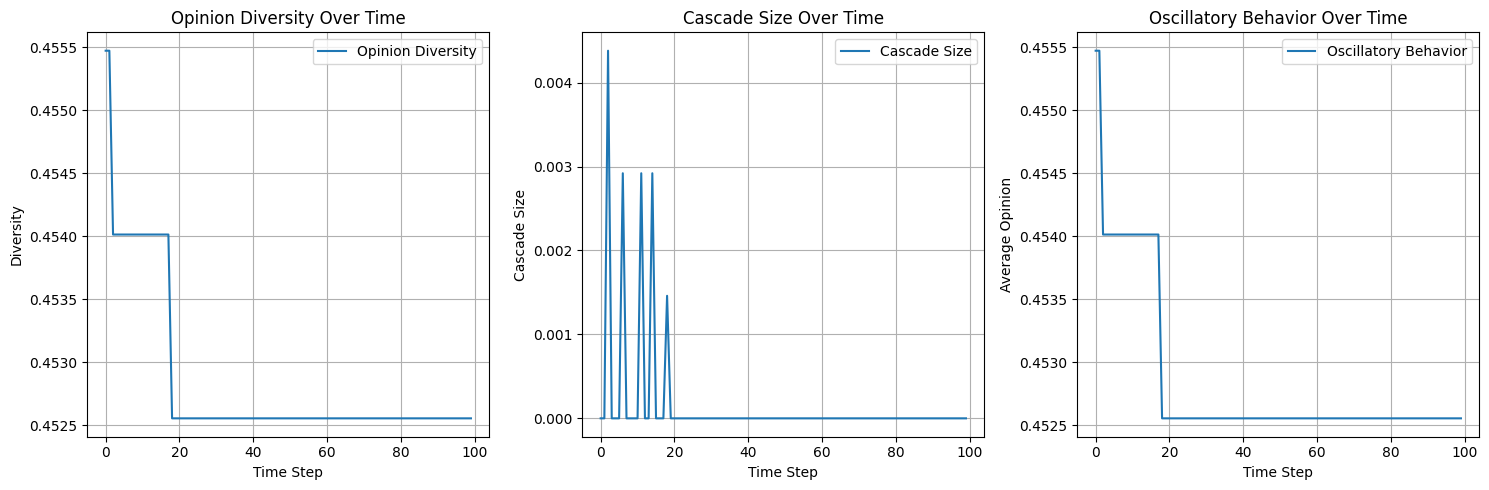

In [ ]:
# Engagement Metrics
dataset['Engagement Metrics'] = dataset['Retweets'].fillna(0) + dataset['Likes'].fillna(0)

# Define Parameters
engagement_metrics = dataset.groupby("Node")["Engagement Metrics"].mean()
influence_weights = engagement_metrics.fillna(0) / engagement_metrics.max()

q = 1.5  # Nonlinearity

#  latency -> random
latencies = np.clip(np.random.normal(3, 1, size=len(unique_users)), 1, None).astype(int)
consensus_threshold = 0.8

# Run Model
model = HNLVoterModel(
    nodes=unique_users,
    hyperedges=hyperedges,
    influence_weights=influence_weights,
    q=q,
    latencies=latencies,
    consensus_threshold=consensus_threshold
)
model.run_simulation(max_steps=100)
model.plot_metrics()


Running simulation for q=0.5, Latency=Gaussian (μ=3, σ=1)
Running simulation for q=0.5, Latency=Gaussian (μ=3, σ=2)
Running simulation for q=1.5, Latency=Gaussian (μ=3, σ=1)
Running simulation for q=1.5, Latency=Gaussian (μ=3, σ=2)
Running simulation for q=2.5, Latency=Gaussian (μ=3, σ=1)
Running simulation for q=2.5, Latency=Gaussian (μ=3, σ=2)


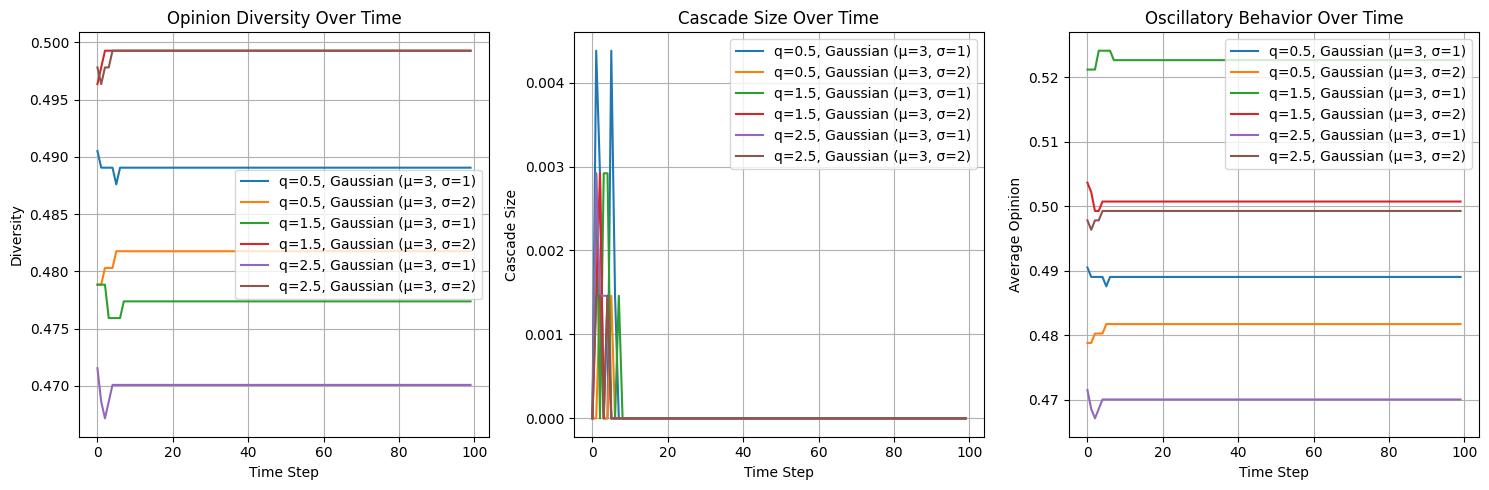

In [ ]:
import matplotlib.pyplot as plt

# Parameters for Testing
q_values = [0.5, 1.5, 2.5]  # Different q values
latency_settings = {
    "Gaussian (μ=3, σ=1)": np.clip(np.random.normal(3, 1, size=len(unique_users)), 1, None).astype(int),
    "Gaussian (μ=3, σ=2)": np.clip(np.random.normal(3, 2, size=len(unique_users)), 1, None).astype(int)
}

# Store results for plotting
results = {}

# Run simulations for all combinations of q and latency
for q in q_values:
    for label, latencies in latency_settings.items():
        print(f"Running simulation for q={q}, Latency={label}")
        model = HNLVoterModel(
            nodes=unique_users,
            hyperedges=hyperedges,
            influence_weights=influence_weights,
            q=q,
            latencies=latencies,
            consensus_threshold=consensus_threshold
        )
        model.run_simulation(max_steps=100)
        results[(q, label)] = model.history  # Store metrics for later plotting

# Plot Combined Metrics
def plot_combined_metrics(results):
    plt.figure(figsize=(15,5))

    # Plot Diversity
    plt.subplot(1, 3, 1)
    for (q, label), history in results.items():
        diversity = [h["diversity"] for h in history]
        plt.plot(diversity, label=f"q={q}, {label}")
    plt.xlabel("Time Step")
    plt.ylabel("Diversity")
    plt.title("Opinion Diversity Over Time")
    plt.legend()
    plt.grid()

    # Plot Cascade Size
    plt.subplot(1, 3, 2)
    for (q, label), history in results.items():
        cascade_size = [h["cascade_size"] for h in history]
        plt.plot(cascade_size, label=f"q={q}, {label}")
    plt.xlabel("Time Step")
    plt.ylabel("Cascade Size")
    plt.title("Cascade Size Over Time")
    plt.legend()
    plt.grid()

    # Plot Oscillatory Behavior
    plt.subplot(1, 3, 3)
    for (q, label), history in results.items():
        oscillation = [h["oscillation"] for h in history]
        plt.plot(oscillation, label=f"q={q}, {label}")
    plt.xlabel("Time Step")
    plt.ylabel("Average Opinion")
    plt.title("Oscillatory Behavior Over Time")
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.show()

# Call the plotting function
plot_combined_metrics(results)
